# Foundations 5: Trigonometry

*Learning path: foundations, part 5 of 9.* [Index](README.md) · Previous: [Polynomials](04-polynomials.ipynb) · Next: [Complex numbers](06-complex-numbers.ipynb)

Trigonometry started as the measurement of triangles and became the mathematics of everything that turns or
repeats: wheels, waves, sound, light, alternating current. You will learn

* angles in degrees and **radians**,
* sine and cosine on the **unit circle**, and the exact values worth knowing,
* the graphs of $\sin$, $\cos$ and $\tan$: period, amplitude and phase,
* the main identities, and how `trigexpand` and `trigreduce` produce them,
* how to solve trigonometric equations,
* how to solve any triangle with the laws of sines and cosines.

## 1. Radians

Galileo, like all of mathematics beyond school, measures angles in **radians**: the length of the arc that the angle
cuts out of a circle of radius 1. A full turn is the whole circumference $2\pi$, so

$$360^\circ = 2\pi, \qquad 180^\circ = \pi, \qquad 1^\circ = \frac{\pi}{180}.$$

To use degrees, multiply by $\pi/180$. Storing that factor in a variable `deg` lets you write `30*deg`:

In [1]:
deg = pi/180;
30*deg
sin(30*deg)
eval(1/deg)

pi/6

1/2

> `sin`: Trigonometric functions, in radians.

57.29577951308232

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

One radian is about $57.3^\circ$. Radians make the formulas of calculus simple (for example the derivative of
$\sin x$ is $\cos x$ only in radians), which is why they are the default.

## 2. The unit circle

Walk around the circle of radius 1, starting at the point $(1, 0)$ and turning counter-clockwise. After turning
through the angle $t$ you are at the point

$$(\cos t, \sin t).$$

That is the definition of cosine and sine: the $x$- and $y$-coordinates of that point. The command
`parametric(X, Y, t, from, to)` draws exactly this: the point $(X, Y)$ for every $t$ from *from* to *to*, with equal
scales on both axes so that the circle looks round. We draw three things and overlay them with `show`:

* the circle itself, $(\cos t, \sin t)$ for $t$ from 0 to $2\pi$;
* the radius at the angle $t = \pi/3$ (60°): the points $(s\cos(\pi/3), s\sin(\pi/3))$ for $s$ from 0 to 1;
* the vertical segment from the $x$-axis up to that point, whose length is $\sin(\pi/3)$.

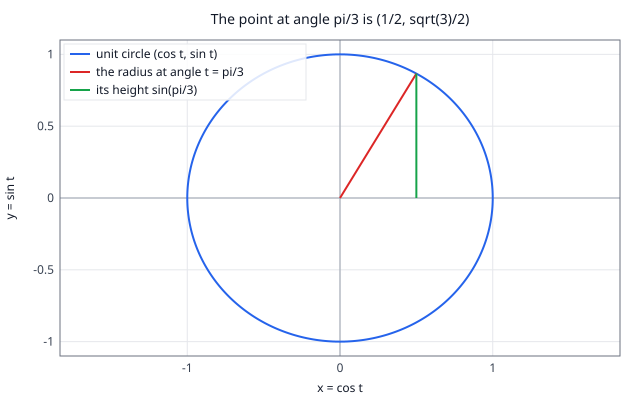

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
circle = parametric(cos(t), sin(t), t, 0, 2*pi);
radius = parametric(s*cos(pi/3), s*sin(pi/3), s, 0, 1);
height = parametric(cos(pi/3), s*sin(pi/3), s, 0, 1);
p = legend(show(circle, radius, height), "unit circle (cos t, sin t)", "the radius at angle t = pi/3", "its height sin(pi/3)");
labels(title(p, "The point at angle pi/3 is (1/2, sqrt(3)/2)"), "x = cos t", "y = sin t")

Reading the plot: the horizontal axis is the $x$-coordinate, which is $\cos t$; the vertical axis is the
$y$-coordinate, $\sin t$. The red radius makes the angle $60^\circ$ with the $x$-axis; its tip is at
$(\cos 60^\circ, \sin 60^\circ) = (1/2, \sqrt{3}/2)$, and the green segment shows the height $\sin 60^\circ$.

Because the point is on a circle of radius 1, Pythagoras gives the most important identity of all:

$$\sin^2 t + \cos^2 t = 1.$$

In [3]:
simplify(sin(t)^2 + cos(t)^2)

1

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

### Exact values

At multiples of $15^\circ$ Galileo knows exact values. `table(expr, k, a, b)` computes an expression for
$k = a, a+1, \ldots, b$; when the expression is a row, the rows stack into a table. Each row below is: the angle in
degrees, its sine, its cosine.

In [4]:
table([15*k, sin(15*k*deg), cos(15*k*deg)], k, 0, 6)

[ 0,                   0,                   1;
 15, sqrt(6)/4-sqrt(2)/4, sqrt(2)/4+sqrt(6)/4;
 30,                 1/2,           sqrt(3)/2;
 45,           sqrt(2)/2,           sqrt(2)/2;
 60,           sqrt(3)/2,                 1/2;
 75, sqrt(2)/4+sqrt(6)/4, sqrt(6)/4-sqrt(2)/4;
 90,                   1,                   0]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The pattern $\sin 0^\circ, \sin 30^\circ, \sin 45^\circ, \sin 60^\circ, \sin 90^\circ = \frac{\sqrt0}{2},
\frac{\sqrt1}{2}, \frac{\sqrt2}{2}, \frac{\sqrt3}{2}, \frac{\sqrt4}{2}$ is an easy way to remember the main ones. The
cosines are the same list backwards.

## 3. Graphs: period, amplitude and phase

Unrolling the circle gives the familiar waves. As $t$ runs once around the circle, $\sin t$ and $\cos t$ go through
one full wave, so both repeat every $2\pi$: their **period** is $2\pi$.

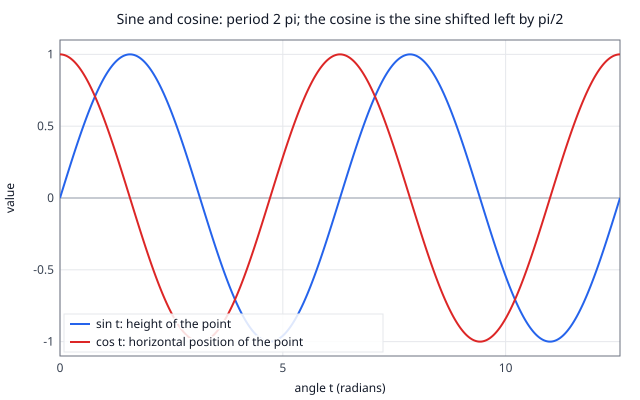

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = plot(sin(t), cos(t), t, 0, 4*pi);
p = legend(p, "sin t: height of the point", "cos t: horizontal position of the point");
labels(title(p, "Sine and cosine: period 2 pi; the cosine is the sine shifted left by pi/2"), "angle t (radians)", "value")

The horizontal axis is the angle $t$ in radians, from 0 to $4\pi$ (two full turns); the vertical axis is the value,
always between $-1$ and $1$. The cosine is the sine moved left by a quarter turn: $\cos t = \sin(t + \pi/2)$.

The general sine wave is $A \sin(\omega t + \varphi)$:

* $A$, the **amplitude**, is the height of the peaks;
* $\omega$, the **angular frequency**, squeezes the wave: the period becomes $2\pi/\omega$;
* $\varphi$, the **phase**, shifts it left by $\varphi/\omega$.

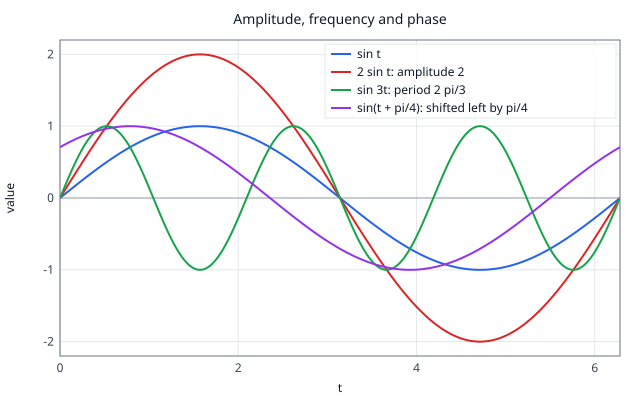

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
p = plot(sin(t), 2*sin(t), sin(3*t), sin(t + pi/4), t, 0, 2*pi);
p = legend(p, "sin t", "2 sin t: amplitude 2", "sin 3t: period 2 pi/3", "sin(t + pi/4): shifted left by pi/4");
labels(title(p, "Amplitude, frequency and phase"), "t", "value")

The tangent $\tan t = \sin t / \cos t$ is the slope of the radius. It is undefined where $\cos t = 0$
($t = \pm\pi/2, \pm 3\pi/2, \ldots$), where the graph has vertical asymptotes, and its period is $\pi$:

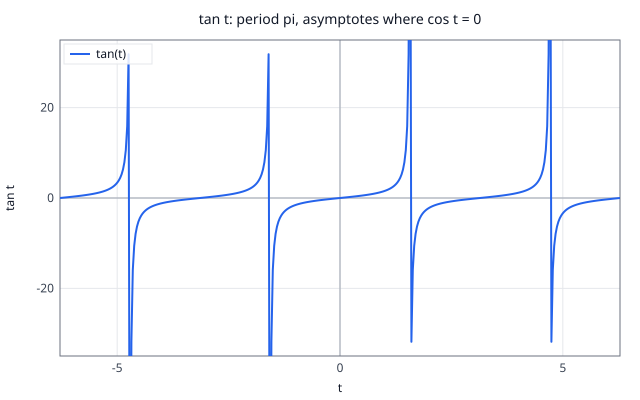

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
labels(title(plot(tan(t), t, -2*pi, 2*pi), "tan t: period pi, asymptotes where cos t = 0"), "t", "tan t")

## 4. Identities

A trigonometric identity is an equation that holds for every angle. The basic ones are the **addition formulas**

$$\sin(a + b) = \sin a\cos b + \cos a \sin b, \qquad \cos(a + b) = \cos a \cos b - \sin a \sin b.$$

`trigexpand` applies them, also to multiples like $2x = x + x$:

In [8]:
trigexpand(sin(a + b))
trigexpand(cos(a + b))
trigexpand(sin(2*x))
trigexpand(cos(2*x))
trigexpand(sin(3*x))

sin(a)*cos(b)+cos(a)*sin(b)

> `trigexpand`: trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

cos(a)*cos(b)-sin(a)*sin(b)

> `trigexpand`: trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

2*sin(x)*cos(x)

> `trigexpand`: trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

cos(x)^2-sin(x)^2

> `trigexpand`: trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

3*sin(x)*cos(x)^2-sin(x)^3

> `trigexpand`: trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

To check whether two expressions are equal, simplify their difference: 0 means they are identical. With
$\sin^2 + \cos^2 = 1$ the double-angle formula $\cos 2x = \cos^2 x - \sin^2 x$ also equals $1 - 2\sin^2 x$:

In [9]:
simplify(trigexpand(cos(2*x)) - (1 - 2*sin(x)^2))

0

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

`trigreduce` goes the other way: it turns products and powers into sums of single waves. That is how one finds, for
example, that the average value of $\sin^2 x$ is $1/2$ (the $\cos 2x$ part averages out):

In [10]:
trigreduce(sin(x)^2)
trigreduce(sin(x)*cos(x))
trigreduce(cos(x)^3)

1/2-cos(2*x)/2

> `trigreduce` (see `trigexpand`): trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

sin(2*x)/2

> `trigreduce` (see `trigexpand`): trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

3*cos(x)/4+cos(3*x)/4

> `trigreduce` (see `trigexpand`): trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

### Adding two waves of the same frequency

$3\sin t + 4\cos t$ is again a single sine wave, $R\sin(t + \varphi)$. Expanding $R\sin(t + \varphi)$ and comparing
coefficients gives $R\cos\varphi = 3$ and $R\sin\varphi = 4$, so $R = \sqrt{3^2 + 4^2} = 5$ and $\varphi$ is the angle
of the point $(3, 4)$, which `atan2(y, x)` computes:

R*(sin(phi)*cos(t)+cos(phi)*sin(t))

> `trigexpand`: trigexpand applies the addition formulas: sin(a+b), cos(2x), tan(a+b), ...

5

> `sqrt`: Square root; sqrt(-1) is the imaginary unit i.

0.9272952180016122

> `atan2`: Angle of the point (x, y), in (-pi, pi].

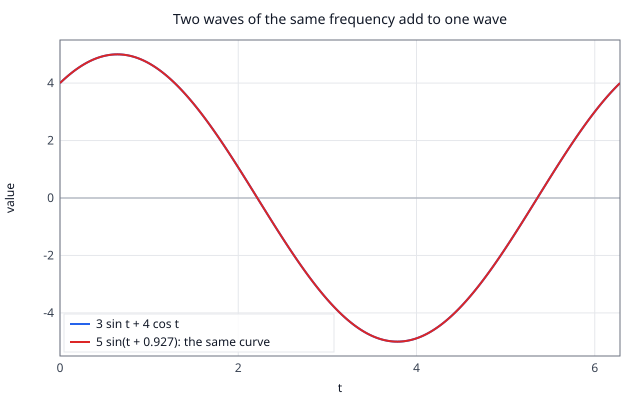

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
trigexpand(R*sin(t + phi))
R = sqrt(3^2 + 4^2)
phi = atan2(4.0, 3.0)
p = plot(3*sin(t) + 4*cos(t), R*sin(t + phi), t, 0, 2*pi);
labels(title(legend(p, "3 sin t + 4 cos t", "5 sin(t + 0.927): the same curve"), "Two waves of the same frequency add to one wave"), "t", "value")

The two curves lie exactly on top of each other. This is why two notes of the same pitch never sound like a new
pitch, only a louder or softer one.

## 5. Trigonometric equations

`solve` handles equations in one of $\sin x$, $\cos x$ or $\tan x$, and returns the solutions in one turn,
$0 \le x < 2\pi$. All other solutions differ from these by whole turns ($2\pi k$):

In [12]:
clear
solve(sin(x) == 1/2, x)
solve(2*cos(x)^2 - cos(x) - 1 == 0, x)
solve(tan(x) == 1, x)

[pi/6, 5*pi/6]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

[0, 2*pi/3, 4*pi/3]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

[pi/4, 5*pi/4]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

Why two solutions for $\sin x = 1/2$? On the unit circle the height $1/2$ is reached at two points, $30^\circ$ and
$150^\circ$, mirror images in the vertical axis. The second equation is a quadratic in $c = \cos x$:
$2c^2 - c - 1 = (2c + 1)(c - 1) = 0$, so $\cos x = 1$ (at $x = 0$) or $\cos x = -1/2$ (at $120^\circ$ and $240^\circ$).

## 6. Solving triangles

For a triangle with sides $a, b, c$ and opposite angles $\alpha, \beta, \gamma$:

* **law of cosines**: $c^2 = a^2 + b^2 - 2ab\cos\gamma$ (Pythagoras when $\gamma = 90^\circ$),
* **law of sines**: $\dfrac{a}{\sin\alpha} = \dfrac{b}{\sin\beta} = \dfrac{c}{\sin\gamma}$.

A triangle has sides 5, 6 and 7. The law of cosines solved for $\cos\gamma$ gives the angle opposite the longest side;
the law of sines then gives $\alpha$; the three angles add up to $180^\circ$:

In [13]:
deg = pi/180;
a = 5; b = 6; c = 7;
gam = acos((a^2 + b^2 - c^2)/(2*a*b))
eval(gam/deg)
alp = asin(a*sin(gam)/c);
eval(alp/deg)
eval(180 - alp/deg - gam/deg)

acos(1/5)

> `acos` (see `asin`): Inverse trigonometric functions.

78.46304096718453

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

44.41530859719297

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

57.12165043562251

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The angles are about $78.5^\circ$, $44.4^\circ$ and $57.1^\circ$. The area is $\frac12 ab\sin\gamma$:

In [14]:
simplify(a*b*sin(gam)/2)
eval(ans)
clear

6*sqrt(6)

> `simplify`: Combines fractions, cancels common factors and applies sin^2 + cos^2 = 1, keeping the simplest form.

14.696938456699067

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Galileo used $\sin(\arccos\tfrac15) = \sqrt{1 - \tfrac{1}{25}} = \tfrac{2\sqrt6}{5}$, so the area is exactly
$6\sqrt6 \approx 14.7$.

## Summary

* Radians: $180^\circ = \pi$. Cosine and sine are the coordinates of the point at angle $t$ on the unit circle.
* $\sin^2 + \cos^2 = 1$; exact values at multiples of $15^\circ$.
* $A\sin(\omega t + \varphi)$: amplitude $A$, period $2\pi/\omega$, phase $\varphi$.
* `trigexpand` applies addition formulas; `trigreduce` turns products into sums; `simplify(a - b)` checks identities.
* `solve` finds the solutions of trigonometric equations in $[0, 2\pi)$.
* The laws of cosines and sines solve any triangle.

**Try it:** find $\sin 75^\circ$ exactly in two ways (`sin(75*deg)` and `trigexpand(sin(45*deg + 30*deg))`). Plot
$\sin t + \sin(1.1\,t)$ for $t$ from 0 to 150: what are the slow "beats" you see? (Hint: `trigreduce` in reverse.)

Next: [Complex numbers](06-complex-numbers.ipynb), where the unit circle becomes a number system.

## Sources

1. I. M. Gelfand and M. Saul, *Trigonometry*, Birkhäuser (2001).
2. G. Van Brummelen, *The Mathematics of the Heavens and the Earth: The Early History of Trigonometry*, Princeton University Press (2009).